# Food Delivery Analytics (Swiggy/Zomato-style)

End-to-end analysis of a synthetic food delivery dataset covering:
- Revenue & order trends
- Customer behavior (repeat rate, RFM-lite)
- Restaurant & cuisine performance
- Delivery time & cancellation analysis
- City-wise insights

Data is synthetically generated (see `data/generate_data.py`) to resemble a real
Swiggy/Zomato order-level dataset — no real user data is used.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

orders = pd.read_csv("../data/food_delivery_orders.csv", parse_dates=["order_date"])
customers = pd.read_csv("../data/customers.csv", parse_dates=["signup_date"])
restaurants = pd.read_csv("../data/restaurants.csv")

orders.head()

,order_id,customer_id,customer_city,restaurant_id,restaurant_name,cuisine,order_date,items_count,order_value,delivery_fee,discount,net_amount,payment_mode,delivery_time_mins,order_status,customer_rating
0,10953,238,Delhi,128,Restaurant_128,Continental,2025-01-01 07:21:00,4,380.42,41.59,57.06,364.95,Cash on Delivery,32,Delivered,5.0
1,4329,1529,Chennai,96,Restaurant_96,Street Food,2025-01-01 07:46:00,2,277.17,36.56,0.00,313.73,UPI,40,Delivered,3.0
2,1407,2262,Chennai,77,Restaurant_77,Street Food,2025-01-01 08:42:00,3,286.42,42.74,0.00,329.16,Debit Card,21,Delivered,5.0
3,7289,990,Bengaluru,142,Restaurant_142,Italian,2025-01-01 08:43:00,7,677.36,24.81,67.74,634.43,UPI,27,Delivered,5.0
4,4720,723,Chennai,166,Restaurant_166,Chinese,2025-01-01 08:50:00,2,203.69,19.44,40.74,182.39,Credit Card,51,Delivered,5.0


## 1. Data Overview & Cleaning

In [2]:
print(orders.shape)
print(orders.dtypes)
orders.isna().sum()

(15000, 16)
order_id                       int64
customer_id                    int64
customer_city                    str
restaurant_id                  int64
restaurant_name                  str
cuisine                          str
order_date            datetime64[us]
items_count                    int64
order_value                  float64
delivery_fee                 float64
discount                     float64
net_amount                   float64
payment_mode                     str
delivery_time_mins             int64
order_status                     str
customer_rating              float64
dtype: object


order_id                 0
customer_id              0
customer_city            0
restaurant_id            0
restaurant_name          0
cuisine                  0
order_date               0
items_count              0
order_value              0
delivery_fee             0
discount                 0
net_amount               0
payment_mode             0
delivery_time_mins       0
order_status             0
customer_rating       5016
dtype: int64

In [3]:
orders["month"] = orders.order_date.dt.to_period("M").astype(str)
orders["day_of_week"] = orders.order_date.dt.day_name()
orders["hour"] = orders.order_date.dt.hour

delivered = orders[orders.order_status == "Delivered"].copy()
print(f"Total orders: {len(orders):,}")
print(f"Delivered: {len(delivered):,} ({len(delivered)/len(orders)*100:.1f}%)")
print(f"Cancelled: {(orders.order_status=='Cancelled').sum():,}")
print(f"Delayed: {(orders.order_status=='Delayed').sum():,}")

Total orders: 15,000
Delivered: 9,984 (66.6%)
Cancelled: 2,498
Delayed: 2,518


## 2. Revenue & Order Trends

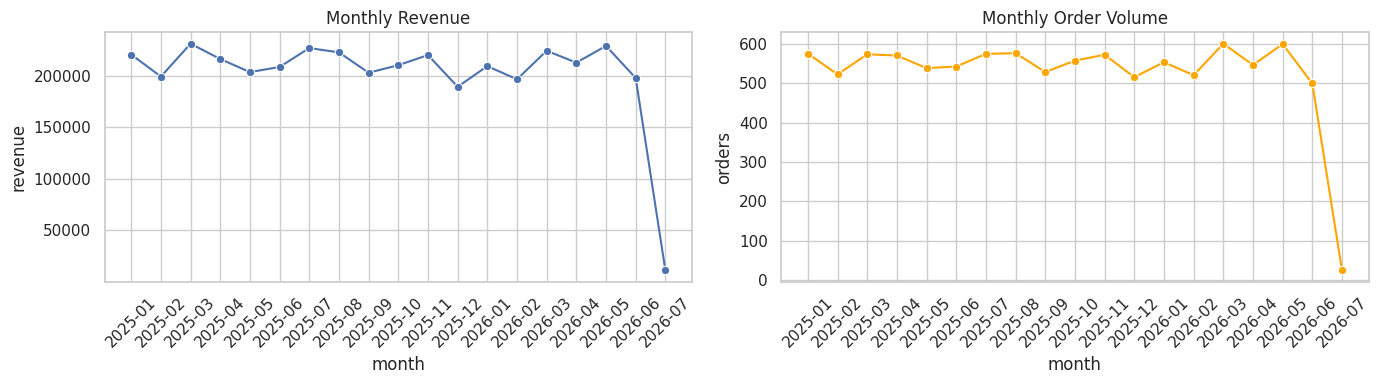

In [4]:
monthly = delivered.groupby("month").agg(
    orders=("order_id","count"),
    revenue=("net_amount","sum"),
    aov=("net_amount","mean")
).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(14,4))
sns.lineplot(data=monthly, x="month", y="revenue", marker="o", ax=ax[0])
ax[0].set_title("Monthly Revenue")
ax[0].tick_params(axis='x', rotation=45)

sns.lineplot(data=monthly, x="month", y="orders", marker="o", color="orange", ax=ax[1])
ax[1].set_title("Monthly Order Volume")
ax[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

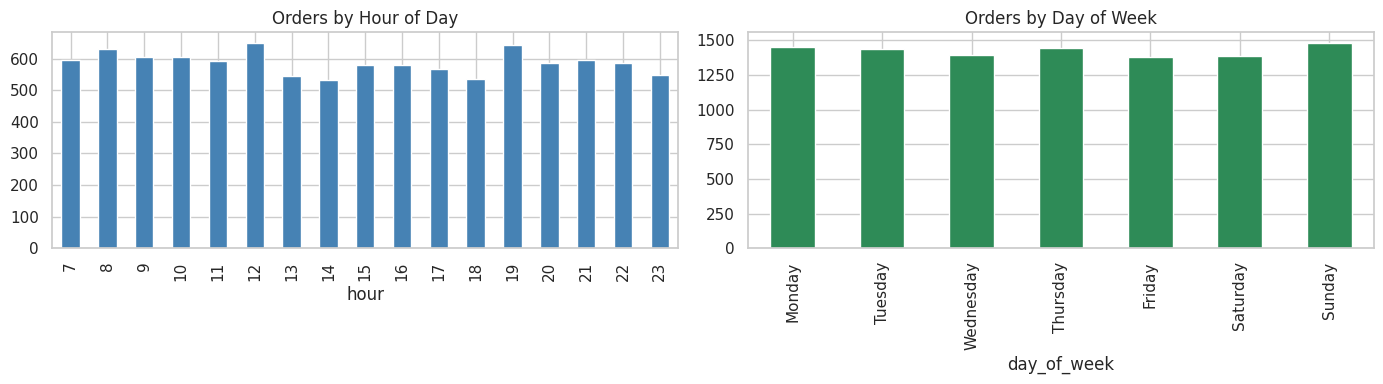

In [5]:
dow_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
hourly = delivered.groupby("hour").size()
dow = delivered.groupby("day_of_week").size().reindex(dow_order)

fig, ax = plt.subplots(1, 2, figsize=(14,4))
hourly.plot(kind="bar", ax=ax[0], color="steelblue")
ax[0].set_title("Orders by Hour of Day")
dow.plot(kind="bar", ax=ax[1], color="seagreen")
ax[1].set_title("Orders by Day of Week")
plt.tight_layout()
plt.show()

## 3. Customer Behavior

In [6]:
cust_orders = delivered.groupby("customer_id").agg(
    orders=("order_id","count"),
    total_spend=("net_amount","sum"),
    last_order=("order_date","max"),
    first_order=("order_date","min")
).reset_index()

repeat_rate = (cust_orders.orders > 1).mean() * 100
print(f"Repeat customer rate: {repeat_rate:.1f}%")
print(f"Average orders per customer: {cust_orders.orders.mean():.2f}")
print(f"Average customer lifetime spend: ₹{cust_orders.total_spend.mean():.2f}")

cust_orders.orders.value_counts().sort_index().head(10)

Repeat customer rate: 92.9%
Average orders per customer: 4.07
Average customer lifetime spend: ₹1563.63


orders
1     174
2     371
3     490
4     496
5     393
6     252
7     153
8      79
9      24
10     14
Name: count, dtype: int64

In [7]:
# Simple RFM-lite segmentation
snapshot_date = delivered.order_date.max() + pd.Timedelta(days=1)
rfm = delivered.groupby("customer_id").agg(
    recency=("order_date", lambda x: (snapshot_date - x.max()).days),
    frequency=("order_id", "count"),
    monetary=("net_amount", "sum")
)

rfm["R_score"] = pd.qcut(rfm.recency, 4, labels=[4,3,2,1]).astype(int)
rfm["F_score"] = pd.qcut(rfm.frequency.rank(method="first"), 4, labels=[1,2,3,4]).astype(int)
rfm["M_score"] = pd.qcut(rfm.monetary, 4, labels=[1,2,3,4]).astype(int)
rfm["RFM_score"] = rfm.R_score + rfm.F_score + rfm.M_score

def segment(score):
    if score >= 10: return "Champions"
    elif score >= 8: return "Loyal"
    elif score >= 6: return "Potential"
    else: return "At Risk"

rfm["segment"] = rfm.RFM_score.apply(segment)
rfm.segment.value_counts()

segment
Champions    693
At Risk      659
Potential    559
Loyal        542
Name: count, dtype: int64

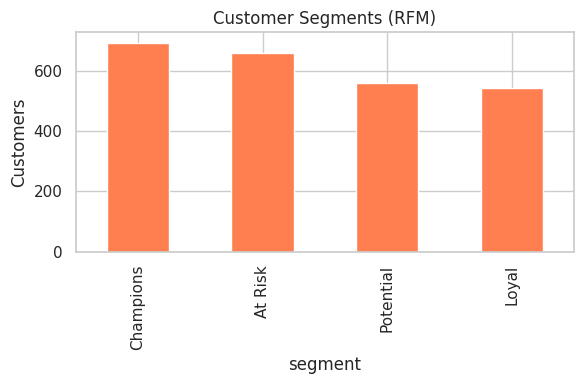

In [8]:
plt.figure(figsize=(6,4))
rfm.segment.value_counts().plot(kind="bar", color="coral")
plt.title("Customer Segments (RFM)")
plt.ylabel("Customers")
plt.tight_layout()
plt.show()

## 4. Restaurant & Cuisine Performance

In [9]:
cuisine_perf = delivered.groupby("cuisine").agg(
    orders=("order_id","count"),
    revenue=("net_amount","sum"),
    avg_rating=("customer_rating","mean")
).sort_values("revenue", ascending=False)

cuisine_perf

,orders,revenue,avg_rating
cuisine,,,
North Indian,1477,567810.88,4.157752
Chinese,1359,514967.28,4.107432
Italian,1113,436606.82,4.170710
Street Food,1042,397396.32,4.170825
Desserts,993,386052.06,4.135952
Biryani,999,378351.47,4.081081
Continental,948,353924.37,4.132911
Fast Food,837,326584.34,4.108722
South Indian,760,293561.57,4.168421


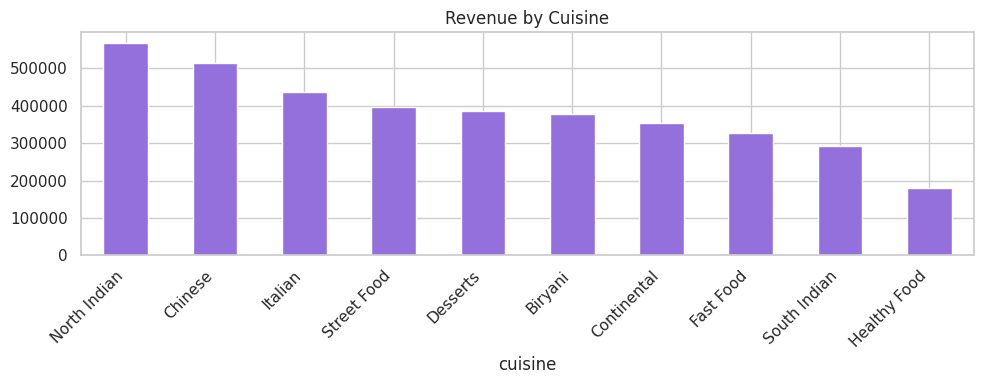

In [10]:
fig, ax = plt.subplots(figsize=(10,4))
cuisine_perf.revenue.plot(kind="bar", color="mediumpurple", ax=ax)
ax.set_title("Revenue by Cuisine")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [11]:
top_restaurants = delivered.groupby("restaurant_name").agg(
    orders=("order_id","count"),
    revenue=("net_amount","sum")
).sort_values("revenue", ascending=False).head(10)
top_restaurants

,orders,revenue
restaurant_name,,
Restaurant_42,81,33154.13
Restaurant_98,78,32403.19
Restaurant_6,78,31960.51
Restaurant_77,76,30920.63
Restaurant_64,81,30616.71
Restaurant_67,76,29303.65
Restaurant_101,76,29019.71
Restaurant_17,78,28733.26
Restaurant_85,74,28591.43


## 5. Delivery Performance

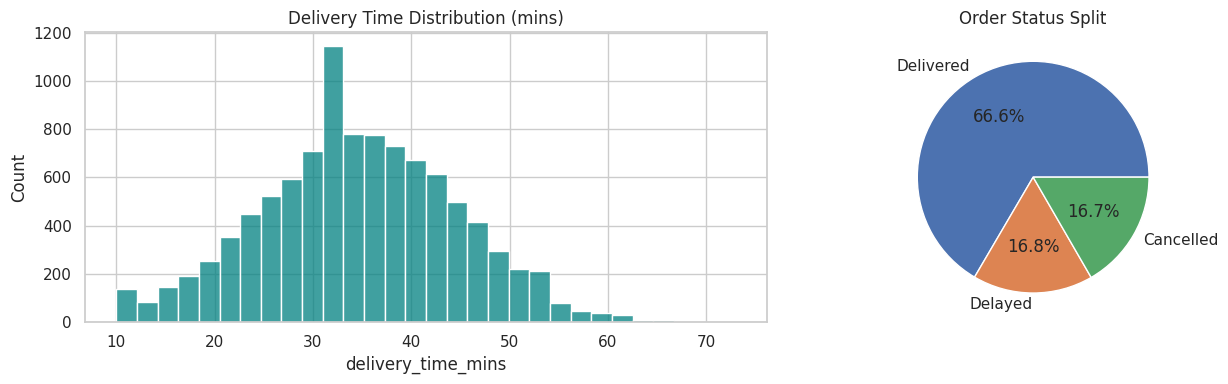

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14,4))
sns.histplot(delivered.delivery_time_mins, bins=30, ax=ax[0], color="teal")
ax[0].set_title("Delivery Time Distribution (mins)")

status_counts = orders.order_status.value_counts()
status_counts.plot(kind="pie", autopct="%1.1f%%", ax=ax[1])
ax[1].set_ylabel("")
ax[1].set_title("Order Status Split")
plt.tight_layout()
plt.show()

## 6. City-wise Insights

In [13]:
city_perf = delivered.groupby("customer_city").agg(
    orders=("order_id","count"),
    revenue=("net_amount","sum"),
    avg_delivery_time=("delivery_time_mins","mean")
).sort_values("revenue", ascending=False)
city_perf

,orders,revenue,avg_delivery_time
customer_city,,,
Bengaluru,1479,567580.76,34.317782
Pune,1507,566146.86,35.002654
Mumbai,1451,562560.70,34.561682
Hyderabad,1445,562542.54,34.215225
Chennai,1438,554441.62,34.271210
Kolkata,1386,537073.74,34.647908
Delhi,1278,485240.81,34.703443


## 7. Key Takeaways

- Revenue and order volume trends highlight seasonality and growth patterns across the period.
- Weekend evenings (Fri–Sun, 7–10 PM) show the highest order density — a signal for staffing and promo timing.
- RFM segmentation identifies **Champions** and **At Risk** cohorts for targeted retention campaigns.
- A handful of cuisines and restaurants drive a disproportionate share of revenue (Pareto effect).
- Delivery delays correlate with lower customer ratings — an operational lever to improve retention.

> Replace the synthetic dataset in `data/` with a real export to plug in actual business data — the notebook logic stays the same.